# BrainScan AI — classification d’images IRM cérébrales

## Block 0 — Setup

In [1]:
import sys, time, json
sys.path.append("..")

from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

from src.data_loader import load_dataset
from src.preprocessing import encode_labels, split_data, normalize, one_hot
from src.model import build_model, save_architecture

SEED = 42
DATA_DIR = "../Data"
np.random.seed(SEED)
tf.random.set_seed(SEED)
Path("../docs").mkdir(parents=True, exist_ok=True)
Path("../models").mkdir(parents=True, exist_ok=True)

## Block 1 — Load and validate images

In [2]:
images, labels, classes = load_dataset(DATA_DIR, seed=SEED)
print("Classes:", classes)
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
assert images.ndim == 4 and images.shape[1:] == (224, 224, 3)
assert len(images) == len(labels)
assert set(labels) == set(classes)

Loaded: 7023 | Skipped: 0 | Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Images: (7023, 224, 224, 3) uint8
Labels: (7023,) <U10


## Block 2 — Exploratory data analysis (EDA)

Images per class: Counter({np.str_('notumor'): 2000, np.str_('pituitary'): 1757, np.str_('meningioma'): 1645, np.str_('glioma'): 1621})
Imbalance ratio (max/min): 1.23


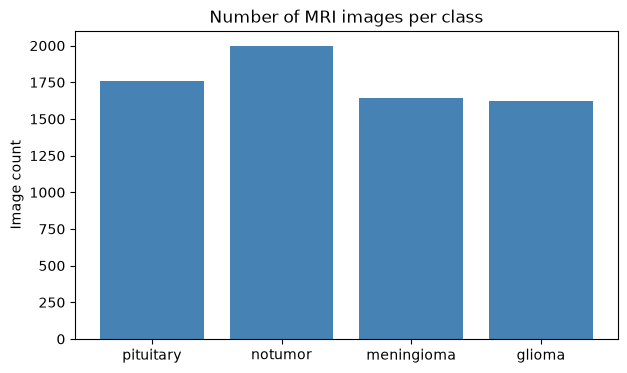

In [ ]:
counts = Counter(labels)
print("Images per class:", counts)
imbalance_ratio = max(counts.values()) / min(counts.values())
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")

plt.figure(figsize=(7, 4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.title("Number of MRI images per class")
plt.ylabel("Image count")
plt.savefig("../docs/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

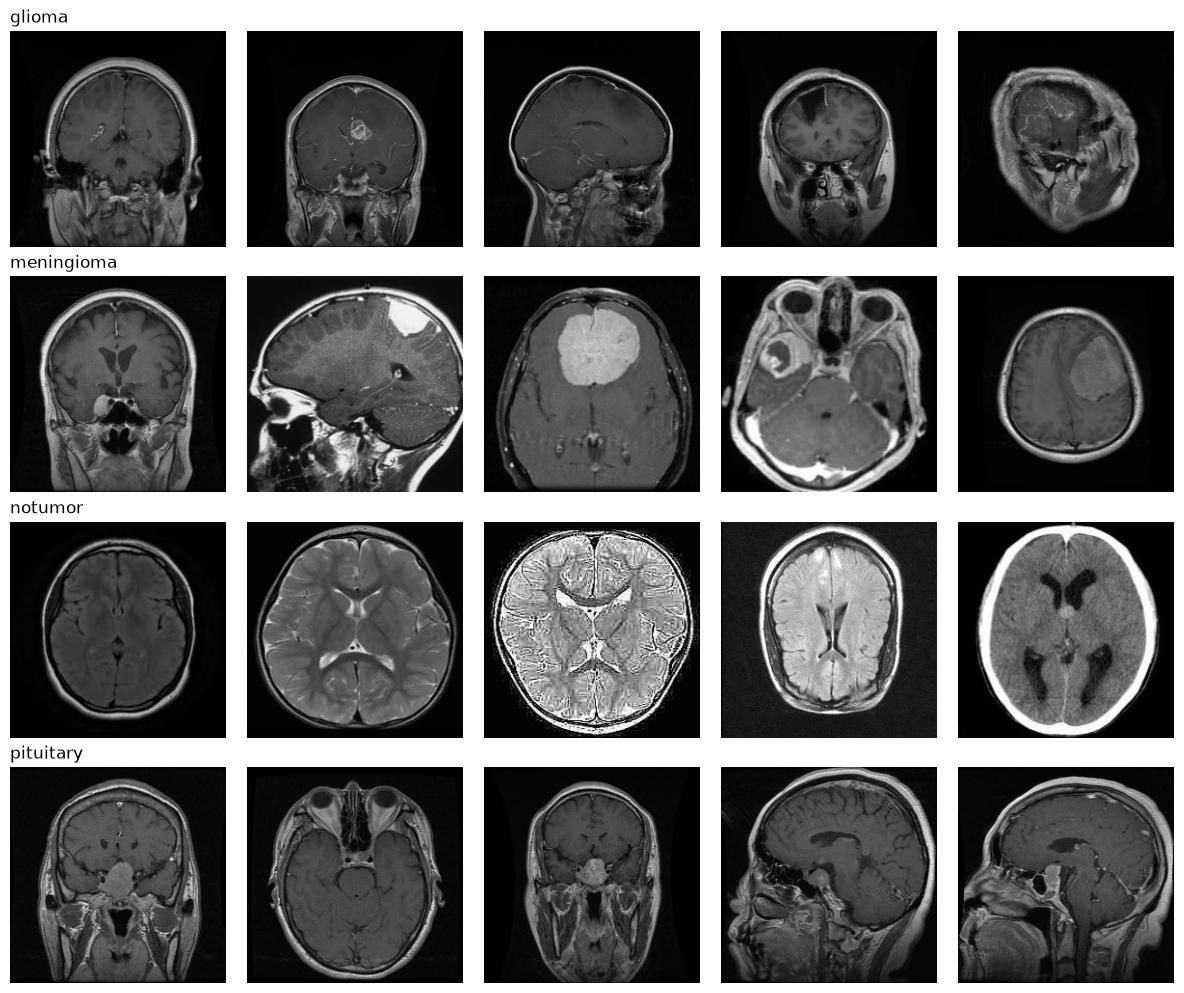

In [15]:
fig, plots = plt.subplots(len(classes), 5, figsize=(12, 2.5 * len(classes)))
for i, cls in enumerate(classes):
    idx = np.flatnonzero(labels == cls)[:5]
    for j, k in enumerate(idx):
        plots[i, j].imshow(images[k])
        plots[i, j].axis("off")
    plots[i, 0].set_title(cls, loc="left")
    
plt.tight_layout()
plt.savefig("../docs/samples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA observations

The observed class counts are 1,621 glioma, 1,645 meningioma, 2,000 no-tumor, and 1,757 pituitary (imbalance ratio ≈ 1.23). This is a modest imbalance, so the baseline uses a stratified split without resampling. Revisit class weights only if validation results show a class-specific problem. After reviewing the sample grid, add a short note here about visible image quality, color, or variation; do not infer diagnosis from appearance alone.

## Block 3 — Encode labels, split, and normalize

In [ ]:
y, le = encode_labels(labels)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(images, y, seed=SEED)

In [ ]:
X_train = normalize(X_train)
X_val = normalize(X_val)
X_test = normalize(X_test)
y_train = one_hot(y_train, len(le.classes_))
y_val = one_hot(y_val, len(le.classes_))
y_test = one_hot(y_test, len(le.classes_))

print("Train:", X_train.shape, X_train.dtype, float(X_train.min()), float(X_train.max()))
print("Labels:", y_train.shape, y_train.dtype)
assert 0.0 <= X_train.min() and X_train.max() <= 1.0
assert len(X_train) == len(y_train)

The test set remains separate from training and model selection. The stratified split preserves the class proportions across train, validation, and test. All splits use the same pixel scaling (`uint8` 0–255 to `float32` 0–1), which must also be used during inference.

## Block 4 — Define and inspect the CNN

In [ ]:
model = build_model(input_shape=X_train.shape[1:], num_classes=len(classes), lr=1e-3)
model.summary()

In [ ]:
try:
    save_architecture(model, "../docs/model_architecture.png")
except Exception as exc:
    print("plot_model could not create the diagram. Check pydot and system Graphviz:", exc)

Baseline choices: ReLU for hidden layers, softmax for four mutually exclusive classes, Adam at learning rate 0.001, categorical cross-entropy, and dropout 0.5. The model starts with four convolution/pooling stages and a 128-unit dense layer. These are initial settings to compare on validation data, not a claim of optimality.

## Block 5 — Train and checkpoint the baseline

In [ ]:
EPOCHS = 30
BATCH_SIZE = 32

callbacks = [
    ModelCheckpoint("../models/best_model.keras", monitor="val_loss", save_best_only=True),
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
]

start = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
)
train_time = time.time() - start
print(f"Training time: {train_time / 60:.1f} min")

## Étape 6 — Évaluer le modèle de référence sur la validation

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy")
ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss")
ax[1].legend()
plt.tight_layout()
plt.savefig("../docs/learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")
y_true = np.argmax(y_val, axis=1)
y_pred = np.argmax(model.predict(X_val, verbose=0), axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("../docs/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print(classification_report(y_true, y_pred, target_names=le.classes_, zero_division=0))

In [ ]:
def show_predictions(indices, title, n=6):
    selected = indices[:n]
    if len(selected) == 0:
        print(f"No examples to display for: {title}")
        return
    fig, axes = plt.subplots(1, len(selected), figsize=(2.5 * len(selected), 3))
    axes = np.atleast_1d(axes)
    for ax, k in zip(axes, selected):
        ax.imshow(X_val[k])
        ax.set_title(f"True: {le.classes_[y_true[k]]}\nPred: {le.classes_[y_pred[k]]}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    filename = title.lower().replace(" ", "_") + ".png"
    plt.savefig(f"../docs/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

show_predictions(np.flatnonzero(y_pred == y_true), "Correct predictions")
show_predictions(np.flatnonzero(y_pred != y_true), "Incorrect predictions")

### Notes d’évaluation

Comparer les courbes d’entraînement et de validation pour repérer un surapprentissage. Dans la matrice de confusion de validation, noter les classes confondues. Examiner la précision, le rappel et le score F1 pour chaque classe; porter une attention particulière au rappel des classes tumorales et aux faux négatifs. Ces mesures décrivent uniquement ce jeu de données et cette séparation; elles ne démontrent pas l’innocuité clinique.

## Block 7 — Compare validation-only experiments

In [ ]:
best_baseline_epoch = int(np.argmin(history.history["val_loss"]))
results = [{
    "expérience": "référence",
    "taux_apprentissage": 1e-3,
    "taille_lot": BATCH_SIZE,
    "augmentation": False,
    "perte_validation": history.history["val_loss"][best_baseline_epoch],
    "exactitude_validation": history.history["val_accuracy"][best_baseline_epoch],
    "époques_exécutées": len(history.history["loss"]),
    "durée_min": round(train_time / 60, 1),
}]
trained = {"référence": model}

def run_experiment(name, lr=1e-3, batch_size=32, augment=False, epochs=30):
    base = build_model(input_shape=X_train.shape[1:], num_classes=len(classes), lr=lr)
    if augment:
        candidate = tf.keras.Sequential([
            tf.keras.layers.Input(shape=X_train.shape[1:]),
            tf.keras.layers.RandomFlip("horizontal"),
            tf.keras.layers.RandomRotation(0.05),
            tf.keras.layers.RandomZoom(0.1),
            base,
        ])
        candidate.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
    else:
        candidate = base

    started = time.time()
    run_history = candidate.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
        verbose=0,
    )
    best_epoch = int(np.argmin(run_history.history["val_loss"]))
    results.append({
        "name": name,
        "lr": lr,
        "batch_size": batch_size,
        "augment": augment,
        "val_loss": run_history.history["val_loss"][best_epoch],
        "val_accuracy": run_history.history["val_accuracy"][best_epoch],
        "epochs_run": len(run_history.history["loss"]),
        "time_min": round((time.time() - started) / 60, 1),
    })
    trained[name] = candidate
    return candidate

In [ ]:
run_experiment("baseline")
run_experiment("lr_3e-4", lr=3e-4)
run_experiment("augmented", augment=True)
results_df = pd.DataFrame(results).sort_values("val_loss")
results_df

Compare at least three runs using validation metrics only. Do not choose settings based on test results: repeatedly using the test set for tuning leaks information and makes the final estimate optimistic. Augmentation is applied to training batches by the model; validation and test images remain unchanged.

## Block 8 — Select and save the final model

In [ ]:
best_name = results_df.iloc[0]["expérience"]
model = trained[best_name]
print("Modèle retenu selon la perte de validation :", best_name)

model.save("../models/final_model.h5")
with open("../models/classes.json", "w", encoding="utf-8") as f:
    json.dump(list(le.classes_), f, ensure_ascii=False, indent=2)

In [ ]:
final_test_loss, final_test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Perte finale sur le test : {final_test_loss:.4f} | Exactitude finale sur le test : {final_test_acc:.4f}")
y_true_test = np.argmax(y_test, axis=1)
y_pred_test = np.argmax(model.predict(X_test, verbose=0), axis=1)

cm = confusion_matrix(y_true_test, y_pred_test)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.savefig("../docs/matrice_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

report_test = classification_report(
    y_true_test, y_pred_test, target_names=le.classes_, zero_division=0, output_dict=True
)
pd.DataFrame(report_test).T.rename(columns={
    "precision": "précision", "recall": "rappel", "f1-score": "score F1", "support": "effectif"
})


Le rapport et la matrice de confusion de test ci-dessus concernent le modèle sélectionné. Le fichier `classes.json` permet à l’inférence de relier les indices de sortie aux noms des classes. La fonction de prédiction et l’application Streamlit seront ajoutées dans `src/` et `app/`.